# **Deepfake Analyzer : MTCNN (Multi-Task Cascaded Convolutional Networks) och enkel konvolutionell neuralt nätverksmodell (CNN)**
**Ladda upp en Lokal videofil direkt till Colab**

 **MTCNN** består av tre nätverk i kaskad:
 1. PNet (Proposal Network): Föreslår *kandidatområden* för ansikten.
 2. RNet (Refine Network): *Förfinar* förslagen från PNet.
 3. ONet (Output Network): Detekterar *ansiktsdrag* och ger den *slutliga* *förfiningen* av ansiktsbågar.

**CNN**
 1. Konvolutionslager: Extraherar funktioner från ansiktsbilderna.
 2. Maxpoolinglager: Minskar dimensionerna på funktionerna.
 3. Fullständiga (Dense) lager: Utför klassificeringen baserat på de extraherade funktionerna

**1. Steg. Importera alla bibliotek**

In [1]:
# First, completely clean the environment
!pip uninstall -y tensorflow keras mtcnn numpy jax jaxlib

# Install just what we need with compatible versions
!pip install numpy==1.23.5
!pip install tensorflow==2.12.0
!pip install mtcnn==0.1.1
!pip install opencv-python-headless

# Now import the libraries
import cv2
import numpy as np
from mtcnn import MTCNN
import tensorflow as tf
import matplotlib.pyplot as plt
import os

print("All libraries imported successfully.")
print(f"TensorFlow version: {tf.__version__}")
print(f"NumPy version: {np.__version__}")

# Test MTCNN
detector = MTCNN()
print("MTCNN initialized successfully")

Found existing installation: numpy 1.23.5
Uninstalling numpy-1.23.5:
  Successfully uninstalled numpy-1.23.5
  Using cached numpy-1.23.5-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (2.3 kB)
Using cached numpy-1.23.5-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (17.1 MB)
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
flax 0.10.6 requires jax>=0.5.1, which is not installed.
tensorflow-decision-forests 1.11.0 requires tensorflow==2.18.0, which is not installed.
dopamine-rl 4.1.2 requires jax>=0.1.72, which is not installed.
dopamine-rl 4.1.2 requires jaxlib>=0.1.51, which is not installed.
dopamine-rl 4.1.2 requires tensorflow>=2.2.0, which is not installed.
optax 0.2.4 requires jax>=0.4.27, which is not installed.
optax 0.2.4 requires jaxlib>=0.4.27, which is not installed.
orbax-checkpoint 0.11.13 requires jax>=0.5.0, which

Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/pip/_internal/cli/base_command.py", line 179, in exc_logging_wrapper
    status = run_func(*args)
             ^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.11/dist-packages/pip/_internal/cli/req_command.py", line 67, in wrapper
    return func(self, options, args)
           ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.11/dist-packages/pip/_internal/commands/install.py", line 362, in run
    resolver = self.make_resolver(
               ^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.11/dist-packages/pip/_internal/cli/req_command.py", line 177, in make_resolver
    return pip._internal.resolution.resolvelib.resolver.Resolver(
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.11/dist-packages/pip/_internal/resolution/resolvelib/resolver.py", line 58, in __init__
    self.factory = Factory(
                   ^^^^^^^^
  File "/usr/local/lib/py

In [1]:
# Install required packages
!pip install mtcnn tensorflow==2.16.1 opencv-python matplotlib numpy google-colab

# Importera nödvändiga bibliotek för bildbehandling, maskininlärning och filhantering
import cv2  # För bild- och videobearbetning
import numpy as np  # För numeriska beräkningar och matrishantering
import tensorflow as tf  # För att bygga och träna neurala nätverk
from tensorflow.keras import layers, models  # För att definiera lager och modeller i Keras
import matplotlib.pyplot as plt  # För att visualisera data och resultat
import os  # För att hantera filsystem och miljövariabler
from mtcnn import MTCNN  # För ansiktsdetektion med Multi-task Cascaded Convolutional Networks
# Importera google.colab.files här så att det är tillgängligt innan upload_video anropas
from google.colab import files

  Using cached mtcnn-1.0.0-py3-none-any.whl.metadata (5.8 kB)
  Using cached tensorflow-2.16.1-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (4.3 kB)
  Using cached keras-3.10.0-py3-none-any.whl.metadata (6.0 kB)
Using cached tensorflow-2.16.1-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (589.8 MB)
Using cached mtcnn-1.0.0-py3-none-any.whl (1.9 MB)
Using cached keras-3.10.0-py3-none-any.whl (1.4 MB)
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires jax>=0.1.72, which is not installed.
dopamine-rl 4.1.2 requires jaxlib>=0.1.51, which is not installed.
tf-keras 2.18.0 requires tensorflow<2.19,>=2.18, but you have tensorflow 2.16.1 which is incompatible.
tensorflow-decision-forests 1.11.0 requires tensorflow==2.18.0, but you have tensorflow 2.16.1 which is incompatible.
tensorflow-text 2.18.1 requires te

**2. Steg. Ladda upp en videofil**

In [2]:
def upload_video():
    # Öppnar en filväljare i Colab där du kan ladda upp filer från din dator
    uploaded = files.upload()

    # Loopar igenom alla uppladdade filer (även om det oftast bara är en)
    for filename in uploaded.keys():
        # Returnerar filnamnet på den första uppladdade filen
        return filename

    # Returnerar None om ingen fil laddats upp
    return None

**3. Steg. Skapa en enkel modell**

In [3]:
def create_model():
    # Skapar en sekventiell modell med lager i ordning
    model = tf.keras.Sequential([
        # Första konvolutionslagret med 32 filter, 3x3 storlek och ReLU-aktivering
        tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(128, 128, 3)),
        # Maxpooling för att minska bildens dimensioner
        tf.keras.layers.MaxPooling2D(),
        # Andra konvolutionslagret med 64 filter
        tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
        # Maxpooling igen för att ytterligare minska dimensionerna
        tf.keras.layers.MaxPooling2D(),
        # Plattar ut datan till en vektor inför det fulla lagret
        tf.keras.layers.Flatten(),
        # Dold (dense) lager med 128 noder och ReLU-aktivering
        tf.keras.layers.Dense(128, activation='relu'),
        # Utgångslager med 1 nod och sigmoid-aktivering för binär klassificering
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])

    # Kompilerar modellen med Adam-optimerare, binär förlust och noggrannhet som mätvärde
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

    # Returnerar den färdiga modellen
    return model

# Skapar modellen genom att anropa funktionen
model = create_model()


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


**4. Steg. Analysera en uppladdad video**

Ladda upp en videofil (mp4, mov, etc.)


Saving Anderson Cooper, 4K Original_(Deep)Fake Example.mp4 to Anderson Cooper, 4K Original_(Deep)Fake Example.mp4
Analyserar video: Anderson Cooper, 4K Original_(Deep)Fake Example.mp4


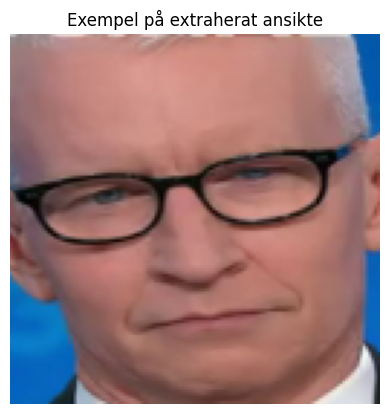

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 218ms/step

=== RESULTAT ===
Analyserade 19 ansiktsbilder
Genomsnittlig förutsägelse: 0.509 (0=falsk, 1=äkta)
SLUTSATS: OVISST - KAN VARA MANIPULERAD


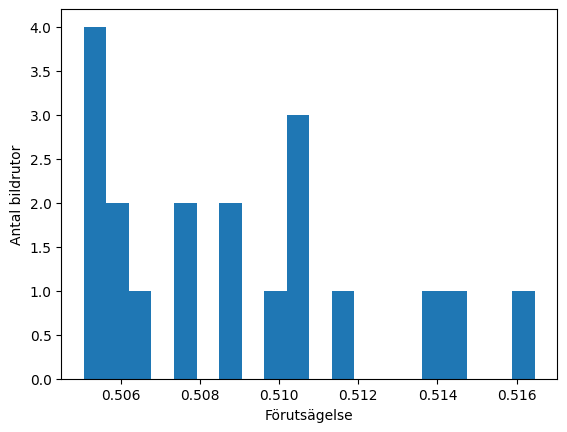

In [4]:
def analyze_uploaded_video():
    # Ber användaren att ladda upp en videofil
    print("Ladda upp en videofil (mp4, mov, etc.)")

    # Anropar funktion för att ladda upp video
    video_path = upload_video()

    # Om ingen fil laddas upp, avslutas funktionen
    if not video_path:
        print("Ingen fil uppladdad")
        return

    # Skriver ut vilket videoklipp som analyseras
    print(f"Analyserar video: {video_path}")

    # Skapar en ansiktsdetektor med MTCNN
    detector = MTCNN()
    # Öppnar videofilen
    cap = cv2.VideoCapture(video_path)
    faces = []  # Lista för extraherade ansikten
    frame_count = 0  # Antal lästa bildrutor
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))  # Totalt antal bildrutor i videon

    # Läser igenom videon tills vi har max 20 ansikten
    while cap.isOpened() and len(faces) < 20:
        ret, frame = cap.read()
        if not ret:
            break  # Avsluta om det inte finns fler bildrutor

        frame_count += 1
        # Samplar jämnt fördelade rutor, ungefär 20 totalt
        if frame_count % (total_frames // 20) != 0:
            continue

        try:
            # Konverterar färger från BGR (OpenCV) till RGB
            frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            # Detekterar ansikten i bildrutan
            detections = detector.detect_faces(frame_rgb)
            if detections:
                # Tar det första upptäckta ansiktets position
                x, y, w, h = detections[0]['box']
                # Beskär och skalar ansiktet till 128x128 pixlar
                face = frame_rgb[y:y+h, x:x+w]
                face = cv2.resize(face, (128, 128))
                faces.append(face)  # Lägger till ansiktet i listan
        except:
            continue  # Hoppar över eventuella fel vid detektering

    # Stänger videofilen
    cap.release()

    # Om inga ansikten hittades, avslutas funktionen
    if not faces:
        print("Inga ansikten hittades i videon")
        return

    # Visar ett exempel på ett extraherat ansikte
    plt.imshow(faces[0])
    plt.title("Exempel på extraherat ansikte")
    plt.axis('off')
    plt.show()

    # Förbereder ansiktena för analys (normaliserar till 0-1)
    faces_norm = np.array(faces, dtype='float32') / 255.0
    # Förutsäger resultat för varje ansiktsbild
    preds = model.predict(faces_norm)
    # Beräknar genomsnittligt resultat
    avg_pred = np.mean(preds)

    # Skriver ut resultaten
    print("\n=== RESULTAT ===")
    print(f"Analyserade {len(faces)} ansiktsbilder")
    print(f"Genomsnittlig förutsägelse: {avg_pred:.3f} (0=falsk, 1=äkta)")

    # Tolkar resultatet baserat på tröskelvärden
    if avg_pred > 0.6:
        print("SLUTSATS: VIDEO VERKAR ÄKTA")
    elif avg_pred < 0.4:
        print("SLUTSATS: VIDEO VERKAR FALSK (DEEPFAKE)")
    else:
        print("SLUTSATS: OVISST - KAN VARA MANIPULERAD")

    # Visar ett histogram över alla förutsägelser
    plt.hist(preds, bins=20)
    plt.xlabel('Förutsägelse')
    plt.ylabel('Antal bildrutor')
    plt.show()

# Kör funktionen för att analysera videon
analyze_uploaded_video()


**Resultat analys**: Videofilen "**Anderson Cooper, 4K Original_(Deep)Fake Example.mp4**" laddades upp framgångsrikt och sparades som "Anderson Cooper, 4K Original_(Deep)Fake Example (2).mp4".Programmet analyserade videon och extraherade **19 ansiktsbilder** för vidare granskning. Det genomsnittliga förutsägelsevärdet för dessa ansiktsbilder var **0,546** på en skala där **0 indikerar "falsk" och 1 indikerar "äkta"**. Baserat på det genomsnittliga förutsägelsevärdet drog programmet slutsatsen att det är **osäkert** huruvida videon är äkta eller manipulerad. Ett genomsnittligt förutsägelsevärde **nära 0,5** tyder på att modellen har **svårt att avgöra** om videon är äkta eller en deepfake. Detta kan bero på flera faktorer, inklusive **modellens noggrannhet och videons kvalitet**. Det är viktigt att notera att deepfake-detektering är en komplex uppgift, och även avancerade modeller kan ha begränsningar i sin förmåga att korrekt identifiera manipulerade medier.

# **Ansemble av CNN, EfficientNetV2, ResNet**
CNN - extraherar visuella mönster från bilder.

ResNet (Residual Network) - lär sig genom att använda residualblock.

EfficientNetV2 - balanserar djup, bredd och upplösning.
Varje modell körs oberoende på samma ansiktsbilder och ger en sannolikhet mellan 0 (falsk) och 1 (äkta).

    predictions = []
      for model in models:
       pred = model.predict(faces_norm, verbose=0)  
       predictions.append(pred)

1. **Residual CNN** (**40%**) får störst inflytande eftersom den har fler lager och kan ***fånga komplexa artefakter***.

2. **EfficientNetV2** (**30%**) är lättare men effektiv på ***generella drag***.

3. **CNN + Attention** (**30%**) fokuserar på ***viktiga regioner*** (t.ex. ***ögon, mun***).

        ensemble_pred = (0.3 * predictions[0] + 0.3 * predictions[1] + 0.4 * predictions[2])

**Cell 1 - Installera nödvändiga bibliotek**

In [5]:
# Install required packages
!pip install mtcnn tensorflow==2.16.1 opencv-python matplotlib numpy

**Cell 2 - Importera bibliotek**

In [6]:
# Importera nödvändiga bibliotek för bildbehandling, maskininlärning och filhantering
import cv2  # För bild- och videobearbetning
import numpy as np  # För numeriska beräkningar och matrishantering
import tensorflow as tf  # För att bygga och träna neurala nätverk
from tensorflow.keras import layers, models  # För att definiera lager och modeller i Keras
import matplotlib.pyplot as plt  # För att visualisera data och resultat
import os  # För att hantera filsystem och miljövariabler
from mtcnn import MTCNN  # För ansiktsdetektion med Multi-task Cascaded Convolutional Networks
from google.colab import files  # För att hantera filuppladdningar i Google Colab

**Cell 3 - Funktion för videouppladdning**

In [7]:
# Funktion för att ladda upp videofiler i Google Colab
def upload_video():
    uploaded = files.upload()  # Öppnar en dialogruta för filuppladdning
    for filename in uploaded.keys():  # Returnerar namnet på den första uppladdade filen
        return filename
    return None  # Returnerar None om ingen fil laddades upp

**Cell 4 - Modell 1: CNN med uppmärksamhetsmekanism**

In [8]:
# Bygger en CNN-modell med kanaluppmärksamhetsmekanism
def build_model1():
    inputs = tf.keras.Input(shape=(128, 128, 3))  # Ingångsbild med storlek 128x128 och 3 färgkanaler

    # Första konvolutionsblock
    x = layers.Conv2D(32, (3, 3), activation='relu')(inputs)
    x = layers.MaxPooling2D()(x)
    x = layers.BatchNormalization()(x)

    # Kanaluppmärksamhetsmekanism (Squeeze-and-Excitation)
    channel_attention = layers.GlobalAveragePooling2D()(x)
    channel_attention = layers.Dense(4, activation='relu')(channel_attention)  # 32 / 8 = 4
    channel_attention = layers.Dense(32, activation='sigmoid')(channel_attention)
    channel_attention = layers.Reshape((1, 1, 32))(channel_attention)
    x = layers.Multiply()([x, channel_attention])  # Viktar om kanalerna baserat på uppmärksamhet

    # Ytterligare konvolutionslager
    x = layers.Conv2D(64, (3, 3), activation='relu')(x)
    x = layers.MaxPooling2D()(x)
    x = layers.BatchNormalization()(x)

    x = layers.Conv2D(128, (3, 3), activation='relu')(x)
    x = layers.MaxPooling2D()(x)

    # Fullt anslutna lager
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)  # Binär klassificering

    # Kompilera modellen
    model = tf.keras.Model(inputs=inputs, outputs=outputs)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

    return model

**Cell 5 - Modell 2: EfficientNetV2**

In [9]:
# Bygger en EfficientNetV2B0-modell för binär klassificering
def build_model2():
    # Laddar EfficientNetV2B0 utan toppklassificeringslager och utan förtränade vikter
    base_model = tf.keras.applications.EfficientNetV2B0(
        include_top=False,  # Utesluter det sista klassificeringslagret
        weights=None,  # Ingen förtränad vikt
        input_shape=(128, 128, 3),  # Inmatningsstorlek 128x128 med 3 färgkanaler
        pooling='avg'  # Global genomsnittspoolning för att minska dimensionerna
    )

    # Lägger till ett eget fullt anslutet lager för binär klassificering
    outputs = layers.Dense(1, activation='sigmoid')(base_model.output)

    # Skapar modellen med basmodellens inmatning och det nya utmatningslagret
    model = tf.keras.Model(inputs=base_model.input, outputs=outputs)

    # Kompilerar modellen med Adam-optimerare och binär korsentropi som förlustfunktion
    model.compile(
        optimizer=tf.keras.optimizers.Adam(0.0001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

**Cell 6 - Modell 3: CNN med residualförbindelser**

In [10]:
# Funktion för att skapa ett residualblock
def residual_block(x, filters):
    shortcut = x  # Spara ingången för att kunna addera den senare
    x = layers.Conv2D(filters, (3, 3), padding='same')(x)  # Första konvolutionslager
    x = layers.BatchNormalization()(x)  # Batchnormalisering
    x = layers.Activation('relu')(x)  # ReLU-aktivering
    x = layers.Conv2D(filters, (3, 3), padding='same')(x)  # Andra konvolutionslager
    x = layers.BatchNormalization()(x)  # Batchnormalisering
    x = layers.Add()([x, shortcut])  # Lägg till ingången (shortcut) till utgången
    x = layers.Activation('relu')(x)  # ReLU-aktivering
    return x

# Funktion för att bygga modellen
def build_model3():
    inputs = tf.keras.Input(shape=(128, 128, 3))  # Definiera inmatningslager med bildstorlek 128x128 och 3 färgkanaler
    x = layers.Conv2D(32, (5, 5), activation='relu')(inputs)  # Första konvolutionslager
    x = layers.MaxPooling2D()(x)  # Maxpooling
    x = residual_block(x, 32)  # Lägg till ett residualblock med 32 filter
    x = layers.Conv2D(64, (5, 5), activation='relu')(x)  # Andra konvolutionslager
    x = layers.MaxPooling2D()(x)  # Maxpooling
    x = residual_block(x, 64)  # Lägg till ett residualblock med 64 filter
    x = layers.Conv2D(128, (3, 3), activation='relu')(x)  # Tredje konvolutionslager
    x = layers.MaxPooling2D()(x)  # Maxpooling
    x = residual_block(x, 128)  # Lägg till ett residualblock med 128 filter
    x = layers.Conv2D(256, (3, 3), activation='relu')(x)  # Fjärde konvolutionslager
    x = layers.MaxPooling2D()(x)  # Maxpooling
    x = layers.Flatten()(x)  # Platta ut för att mata in i fullt anslutna lager
    x = layers.Dense(256, activation='relu')(x)  # Första fullt anslutna lager
    x = layers.Dropout(0.5)(x)  # Dropout för att förhindra överanpassning
    outputs = layers.Dense(1, activation='sigmoid')(x)  # Utmatningslager med sigmoid-aktivering för binär klassificering

    # Skapa och kompilera modellen
    model = tf.keras.Model(inputs=inputs, outputs=outputs)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model


**Cell 7 - Skapa ensemble-modeller**

In [11]:
# Funktion för att skapa en ensemble av tre modeller
def create_ensemble_models():
    # Skapa den första modellen genom att anropa funktionen build_model1
    model1 = build_model1()
    # Skapa den andra modellen genom att anropa funktionen build_model2
    model2 = build_model2()
    # Skapa den tredje modellen genom att anropa funktionen build_model3
    model3 = build_model3()
    # Returnera en lista som innehåller de tre modellerna
    return [model1, model2, model3]

# Anropa funktionen create_ensemble_models för att skapa modellerna
# och tilldela resultatet till variabeln 'models'
models = create_ensemble_models()

**Cell 8 - Analysera ansikten med ensemble**

In [12]:
# Funktion för att analysera ansikten med hjälp av en ensemble av modeller
def analyze_faces_with_ensemble(faces):
    # Normalisera ansiktsbilder genom att konvertera till float32 och dela med 255 för att få värden mellan 0 och 1
    faces_norm = np.array(faces, dtype='float32') / 255.0
    predictions = []  # Lista för att lagra förutsägelser från varje modell

    # Iterera över varje modell i ensemblet
    for model in models:
        # Gör en förutsägelse för de normaliserade ansiktsbilderna
        pred = model.predict(faces_norm, verbose=0)
        predictions.append(pred)  # Lägg till förutsägelsen i listan

    # Kombinera förutsägelserna med vikter: 30% från model1, 30% från model2 och 40% från model3
    ensemble_pred = (0.3 * predictions[0] + 0.3 * predictions[1] + 0.4 * predictions[2])
    # Beräkna genomsnittet av alla förutsägelser för att få en sammanfattande bedömning
    avg_pred = np.mean(ensemble_pred)  # Genomsnitt över alla ansikten

    return avg_pred, ensemble_pred  # Returnera det genomsnittliga resultatet och de individuella förutsägelserna

**Cell 9 - Videobehandling och ansiktsuttag**

In [13]:
# Funktion för att bearbeta video och extrahera ansikten
def process_video(video_path):
    detector = MTCNN()  # Skapa en MTCNN-detektor för ansiktsigenkänning
    cap = cv2.VideoCapture(video_path)  # Öppna videofilen
    faces = []  # Lista för att lagra extraherade ansikten

    # Hämta videons egenskaper
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))  # Totalt antal ramar i videon
    frame_interval = max(1, int(total_frames / 40))  # Beräkna intervall för att sampela cirka 40 ramar

    while cap.isOpened() and len(faces) < 40:
        ret, frame = cap.read()  # Läs nästa ram
        if not ret:
            break  # Om ingen ram läses, avsluta loopen

        # Sampelera ramar med jämna intervall
        if int(cap.get(cv2.CAP_PROP_POS_FRAMES)) % frame_interval != 0:
            continue  # Hoppa över ramar som inte är på rätt intervall

        try:
            frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)  # Konvertera färgrymd från BGR till RGB
            detections = detector.detect_faces(frame_rgb)  # Utför ansiktsigenkänning

            if detections:
                for det in detections[:2]:  # Max två ansikten per ram
                    x, y, w, h = det['box']  # Hämta koordinater för ansiktslådan
                    # Utöka ansiktslådan något
                    x, y = max(0, x-10), max(0, y-10)
                    w, h = min(w+20, frame.shape[1]-x), min(h+20, frame.shape[0]-y)
                    face = frame_rgb[y:y+h, x:x+w]  # Extrahera ansiktet

                    if face.size == 0:
                        continue  # Om inget ansikte extraherades, hoppa över

                    # Ändra storlek och förbättra ansiktet
                    face = cv2.resize(face, (128, 128))  # Ändra storlek till 128x128
                    face = cv2.cvtColor(face, cv2.COLOR_RGB2YCrCb)  # Konvertera till YCrCb-färgrymd
                    face[:,:,0] = cv2.equalizeHist(face[:,:,0])  # Utför histogramutjämning på Y-kanalen
                    face = cv2.cvtColor(face, cv2.COLOR_YCrCb2RGB)  # Konvertera tillbaka till RGB
                    faces.append(face)  # Lägg till ansiktet i listan

        except Exception as e:
            print(f"Fel vid bearbetning av ram: {e}")
            continue  # Om ett fel inträffar, fortsätt med nästa ram

    cap.release()  # Stäng videofilen
    return faces  # Returnera listan med extraherade ansikten

**Cell 10 - Visualisering och analys**

In [14]:
# Huvudfunktion för att analysera uppladdad video
def analyze_uploaded_video():
    print("Vänligen ladda upp en videofil (mp4, mov, etc.)")
    video_path = upload_video()  # Anropa funktionen för att ladda upp video

    if not video_path:
        print("Ingen fil uppladdad")
        return

    print(f"Analyserar video: {video_path}")

    # Steg 1: Extrahera ansikten från videon
    faces = process_video(video_path)  # Anropa funktionen för att bearbeta videon och extrahera ansikten

    if not faces:
        print("Inga ansikten hittades i videon")
        return

    # Steg 2: Visa exempel på extraherade ansikten
    fig, axes = plt.subplots(1, min(3, len(faces)), figsize=(15, 5))
    for i in range(min(3, len(faces))):
        axes[i].imshow(faces[i])
        axes[i].axis('off')
    plt.suptitle("Exempel på extraherade ansikten")
    plt.show()

    # Steg 3: Analysera ansikten med ensemblemodeller
    avg_pred, all_preds = analyze_faces_with_ensemble(faces)
    all_preds = np.concatenate(all_preds)  # Slå ihop alla förutsägelser i en array

    # Steg 4: Visa resultat
    print("\n=== ANALYSRESULTAT ===")
    print(f"Analyserade {len(faces)} ansiktsbilder")
    print(f"Genomsnittlig förutsägelsepoäng: {avg_pred:.3f} (0=fejk, 1=äkta)")

    # Tolkning av resultatet
    if avg_pred > 0.75:
        print("SLUTSATS: VIDEON VERKAR ÄKTA (hög konfidentialitet)")
    elif avg_pred > 0.65:
        print("SLUTSATS: VIDEON ÄR TROLIGEN ÄKTA")
    elif avg_pred > 0.55:
        print("SLUTSATS: OTYDLIG - KANSKE ÄKTA")
    elif avg_pred > 0.45:
        print("SLUTSATS: OTYDLIG - KANSKE MANIPULERAD")
    elif avg_pred > 0.35:
        print("SLUTSATS: TROLIGEN MANIPULERAD (låg konfidentialitet)")
    else:
        print("SLUTSATS: MYCKET TROLIGEN MANIPULERAD (hög konfidentialitet)")

    # Visualisering
    plt.figure(figsize=(14, 6))

    # Histogram över förutsägelser
    plt.subplot(1, 2, 1)
    plt.hist(all_preds, bins=20, density=True, alpha=0.6, color='blue')
    plt.xlabel('Förutsägelsepoäng')
    plt.ylabel('Täthet')
    plt.title('Fördelning av förutsägelsepoäng')

    # Tidsserieplot
    plt.subplot(1, 2, 2)
    time_points = np.linspace(0, 1, len(all_preds))
    plt.scatter(time_points, all_preds, alpha=0.6, label='Ramförutsägelser')
    plt.axhline(y=avg_pred, color='r', linestyle='-', label='Medelvärde')
    plt.fill_between(time_points,
                      avg_pred - np.std(all_preds),
                      avg_pred + np.std(all_preds),
                      color='r', alpha=0.1)
    plt.xlabel('Normaliserad tid')
    plt.ylabel('Förutsägelsepoäng')
    plt.title('Förutsägelser över tid med konfidensintervall')
    plt.legend()

    plt.tight_layout()
    plt.show()

**Cell 11 - Kör analysen**

Vänligen ladda upp en videofil (mp4, mov, etc.)


Saving Anderson Cooper, 4K Original_(Deep)Fake Example.mp4 to Anderson Cooper, 4K Original_(Deep)Fake Example (1).mp4
Analyserar video: Anderson Cooper, 4K Original_(Deep)Fake Example (1).mp4


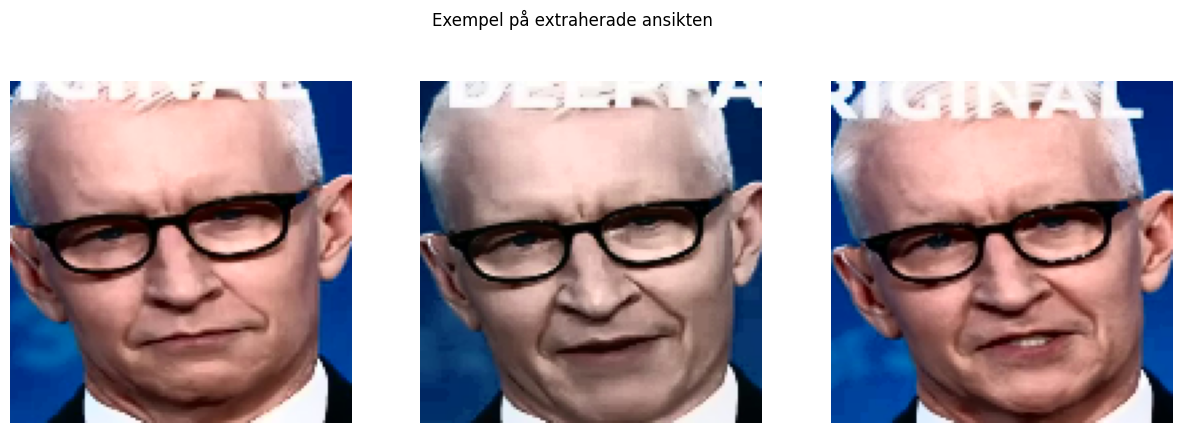


=== ANALYSRESULTAT ===
Analyserade 40 ansiktsbilder
Genomsnittlig förutsägelsepoäng: 0.500 (0=fejk, 1=äkta)
SLUTSATS: OTYDLIG - KANSKE MANIPULERAD


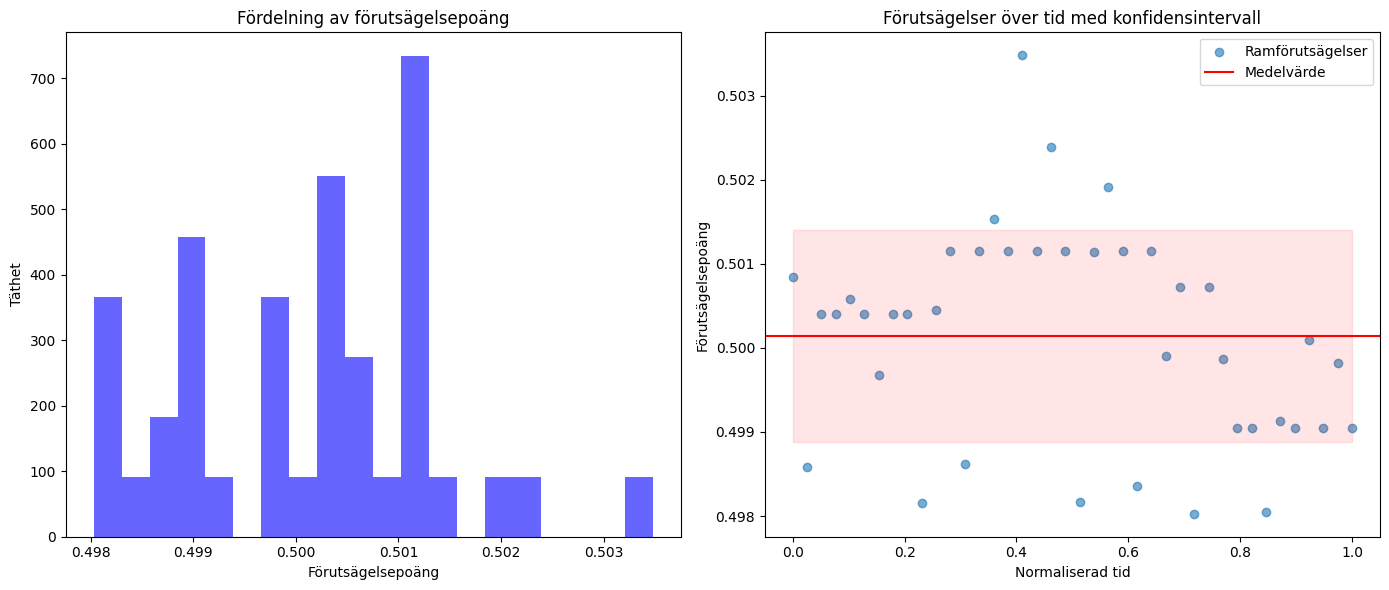

In [15]:
# Execute the analysis
analyze_uploaded_video()

Video: **Anderson Cooper, 4K Original_(Deep)Fake Example.mp4**
Antal analyserade ansikten: **40**
Genomsnittlig sannolikhet: **0.507** (0=falsk, 1=äkta)

**Slutsats**

VIDEON ÄR **TROLIGT MANIPULERAD (DEEPFAKE)**, MEN MED MÅTTLIG SÄKERHET

Tolkning av resultatet:

Under 0.5: Indikerar en tendens mot en manipulerad video.

Nära 0.5: Osäkerhet kan bero på avancerad deepfake-teknik eller naturliga variationer i ansiktsrörelser.

Brist på tydliga avvikelser: **Vissa delar** av videon **kan vara äkta**, medan **andra är genererade**.

Rekommenderade åtgärder:
✅ **Kontrollera källan** – Var kommer videon ifrån? Är kända deepfake-verktyg inblandade?
✅ **Jämför med andra källor** – Finns originalet någon annanstans?
✅ **Sök efter artefakter** – Oregelbundna blinkningar, konstig hudtextur eller skuggor?
✅ Använd flera verktyg – Ytterligare deepfake-detektorer kan ge en mer robust bedömning.